© 2026 by Tamás Takács is licensed under CC BY-NC-SA 4.0. To view a copy of this license, visit https://creativecommons.org/licenses/by-nc-sa/4.0/

# **First Network**

**Deep Network Development W09**

**Topic:** Imputation, standardisation and one-hot encoding of a CSV file, and a multilayer perceptron trained with a hand-written loop.

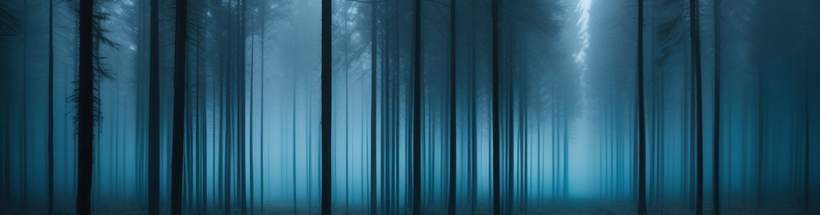

## **Task overview**

Each row of the three files is a customer. The columns `age`, `income`, `tenure_months` and `score` are numeric. The columns `region`, `plan` and `channel` hold categories. `train.csv` also has the label `churn`, 1 for a customer who left and 0 for one who stayed. `test.csv` and `test2.csv` hold other customers, without the label. The task is to predict `churn` from the other seven columns.

| Part | Task | Points |
|---|---|---:|
| a | The preprocessing, checked number by number | 30 |
| b | Churn predictions for the customers of `test.csv` | 35 |
| c | The same model, on the customers of `test2.csv` | 35 |

Part a has exactly one right answer. Parts b and c are graded on how many of your predictions are correct. A model that is right 70% of the time scores about 70% of the marks.

**Both test files are class balanced.** In each, half of the customers left. Submitting all zeros therefore scores 50%. At the churn rate of the full customer register, 36%, it would score about 64%.



## **The reference network**

The diagram below shows the network to build. The 17 columns of the feature matrix go into `nn.Linear(17, 32)`, followed by ReLU, then `nn.Linear(32, 16)`, followed by ReLU, then `nn.Linear(16, 1)`. Its single output per row is the logit `z`. Each line in the diagram is one weight. Some units of the two hidden layers are left out of the drawing.

Train it with the loss `nn.BCEWithLogitsLoss` and the optimizer Adam at a learning rate of `0.001`, for 40 epochs on minibatches of 128 rows. Predict churn for a customer when `torch.sigmoid(z) > 0.5`. This network scores between 65% and 70% on the test set. A different architecture is allowed.

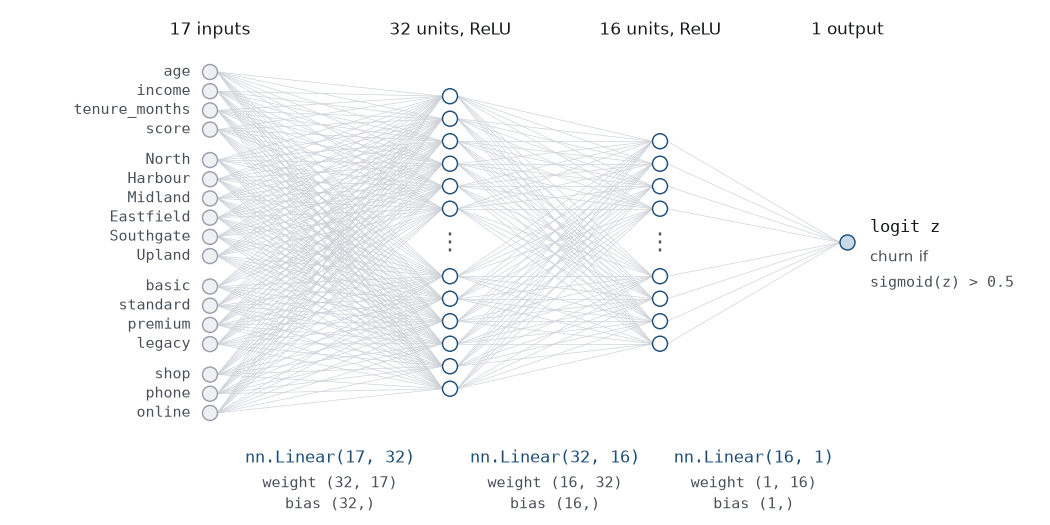

## **The preprocessing recipe**

Part a has one right answer because the recipe is fixed. Follow it exactly, in this order. Use it for parts b and c too.

1. **Imputation.** Replace every missing numeric value with the **median of that column in `train.csv`**, computed over the values that are present. Use the training median on the test files too. Nothing computed from a test file goes into the preprocessing.
2. **Standardisation.** Subtract the mean and divide by the standard deviation, both computed on the **training** columns **after** imputing. The standard deviation divides by the count, not by the count minus one.
3. **One-hot encoding.** Encode the three categorical columns, in the order `region`, `plan`, `channel`, and within each in the order: `North, Harbour, Midland, Eastfield, Southgate, Upland`, then `basic, standard, premium, legacy`, then `shop, phone, online`.
4. **Concatenation.** Place the four standardised numeric columns first, then the one-hot blocks in that order. That gives **17 columns**.

**Part a, 20 rows.**

- row `0`: how many rows are in `train.csv`
- row `1`: how many rows are in `test.csv`
- row `2`: how many feature columns after step 4
- rows `3..6`: the imputation median of `age`, `income`, `tenure_months`, `score`, times 100
- rows `7..10`: the training mean of each numeric column after imputing, times 100
- rows `11..14`: the training standard deviation of each, times 100
- rows `15..19`: the standardised value at these positions of the training matrix, times 100, in this order: `(0, 0)`, `(5, 1)`, `(17, 2)`, `(123, 3)`, `(999, 0)`. The first number is the row of `train.csv` in file order. The second is the column index from step 4.

**Part b, one row per row of `test.csv`, in file order.** Report `1` if you predict the customer left and `0` if not.

**Part c, one row per row of `test2.csv`, in file order.** Apply the model of part b, without retraining, to a second test set of customers who are in neither `train.csv` nor `test.csv`. Build their features with the **training** medians, means and standard deviations.

## **Useful Links**

- [`torch.nn` module reference](https://pytorch.org/docs/stable/nn.html)
- [`nn.BCEWithLogitsLoss`](https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html)
- [Optimizers](https://pytorch.org/docs/stable/optim.html)
- [Tensors from NumPy](https://pytorch.org/docs/stable/generated/torch.from_numpy.html)

## **Setup and data**

In [18]:
# ══════════════════════════════════════════════════════════
# Setup. DO NOT MODIFY.
# ══════════════════════════════════════════════════════════
import csv
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn

torch.manual_seed(42)
np.random.seed(42)

def write_submission(filename, rows):
    """Write [(id, target), ...] as a DOCK-ready CSV."""
    with open(filename, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["id", "target"])
        for row_id, target in rows:
            writer.writerow([int(row_id), int(target)])
    print(f"wrote {filename}: {len(rows)} rows")

def _find(name):
    here = Path(name)
    return here if here.exists() else Path("data") / name

def load(name):
    with open(_find(name), newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

NUMERIC = ["age", "income", "tenure_months", "score"]
CATEGORICAL = ["region", "plan", "channel"]
CATEGORIES = {
    "region": ["North", "Harbour", "Midland", "Eastfield", "Southgate", "Upland"],
    "plan": ["basic", "standard", "premium", "legacy"],
    "channel": ["shop", "phone", "online"],
}

train = load("train.csv")
test = load("test.csv")
test2 = load("test2.csv")

print(f"train {len(train)} rows (with churn), test {len(test)}, test2 {len(test2)}")
print("train columns:", list(train[0]))
print("churn rate in train:", sum(int(r["churn"]) for r in train) / len(train))

train 4974 rows (with churn), test 1534, test2 3000
train columns: ['age', 'income', 'tenure_months', 'score', 'region', 'plan', 'channel', 'churn']
churn rate in train: 0.5


---
## **Part a: The preprocessing (30 points)**

Part a checks the preprocessing before any network is trained: the row counts, the training statistics and five entries of the training matrix.

Submission: `part1_submission.csv`, 20 rows, uploaded to part a.

In [ ]:
part1 = [[i, 0] for i in range(20)]

# ── Your code starts here ──
# Impute, standardise, one-hot encode and concatenate, in that order. Build the
# training matrix, then report the counts, the medians, the means, the deviations
# and the five cells.

part1[0][1] = len(train)
print(part1[0][1])

part1[1][1] = len(test)
print(part1[1][1])

write_submission("part1_submission.csv", part1)

4974
4974
1534
1534
wrote part1_submission.csv: 20 rows


---
## **Part b: Train the network (35 points)**

Build the network of the diagram, train it on `train.csv` and predict for every row of `test.csv` in file order.

Write the training loop yourself. Every epoch, shuffle the training rows and cut them into minibatches of 128. For each minibatch, zero the gradients, compute the loss of the network's outputs against the labels, call `backward()` on it and take a step of the optimizer. That is two loops, one over epochs and one over minibatches, around those four statements.

Submission: `part2_submission.csv`, one row per test row, uploaded to part b.

In [20]:
part2 = [(i, 0) for i in range(len(test))]

# ── Your code starts here ──

write_submission("part2_submission.csv", part2)
part2[:8]

wrote part2_submission.csv: 1534 rows


[(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0)]

---
## **Part c: A second test set (35 points)**

`test2.csv` holds further customers, drawn from the same population as the other two files and in neither of them. **Do not retrain.** Build their feature matrix with the recipe of part a, using the medians, means and standard deviations of `train.csv`. Predict with the network trained in part b.

A model therefore scores about the same on both test files. The two accuracies of the reference network differ by less than two percentage points.

Submission: `part3_submission.csv`, one row per row of `test2.csv`, uploaded to part c.

In [21]:
part3 = [(i, 0) for i in range(len(test2))]

# ── Your code starts here ──

write_submission("part3_submission.csv", part3)
part3[:8]

wrote part3_submission.csv: 3000 rows


[(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0)]

---
## **Submission**

Upload each CSV to its own part on DOCK.

